Single allele groupped structue models.

In [1]:
import pomegranate.io
from pomegranate import *


In [2]:
import matplotlib.pyplot as plt
import numpy as np
import seaborn as sns
import pandas as pd
import logomaker
import sys
import seaborn as sns
PATH_TO_PREDICTOR_HOME = "../.."
sys.path.append(PATH_TO_PREDICTOR_HOME)
METHOD = "hmm_pomegranate"


 1. Read data

In [3]:
TOTAL_SPLITS = 5 # number of splits in data
DATA_PATH_BASE = 'G:/My Drive/Work/ITMO/data'
# DATA_PATH_BASE = 'D:/Google Drive/Work/ITMO/data' #windows
# DATA_PATH_BASE = '/home/denklewer/Data' #ubuntu
EXPERIMENT_NAME = 'multiple_single_allele_models'
DATA_SCENARIO = "simulated_preprocessed" # ["preprocessed_IEDB", "simulated","simulated_preprocessed", 'MixMHCpred]
PREPROCESSED_DATA_PATH = f'{DATA_PATH_BASE}/{EXPERIMENT_NAME}/per_length_per_kfold_split/' # work laptop

DUMMY_ALLELE_NAME = "dummy_allele"
SIMULATED_DATA_PATH_BASE = f'{DATA_PATH_BASE}/{EXPERIMENT_NAME}/simulated_data/'

SIMULATED_PREPROCESSED_DATA_PATH_BASE = f'{DATA_PATH_BASE}/{EXPERIMENT_NAME}/per_length_per_kfold_split/' # work laptop

#simulated_scenario = "five_different_motifs"
# simulated_exact_file = "sim_data_motifs_5_ratio_(0.05, 0.15, 0.25, 0.25, 0.3)_lengths_(8,)_noize_0.csv"
#simulated_exact_file = "sim_data_motifs_5_ratio_(0.05, 0.05, 0.05, 0.05, 0.8)_lengths_(8,)_noize_0.csv"
simulated_scenario = "random_cores"
simulated_exact_file = "sim_data_motifs_2_ratio_(0.5, 0.5)_lengths_(8,)_noize_0.csv"
MIXMHCPRED_DATA_PATH = f"{DATA_PATH_BASE}/Binding data/MixMHC2pred/Sup1_list_of_peptides_identified_antiDR.txt"
mixmhcpred_mixture_to_work_with = 'Intensity 3808-HMC_II'
MIXMHCPHRED_DUMMY_ALLELE_NAME = "mixMHC_dummy_allele"


if DATA_SCENARIO == "preprocessed_IEDB":
    DATA_PATH = PREPROCESSED_DATA_PATH
elif DATA_SCENARIO == "MixMHCpred":
    DATA_PATH = MIXMHCPRED_DATA_PATH
elif DATA_SCENARIO == "simulated_preprocessed":
    DATA_PATH = SIMULATED_PREPROCESSED_DATA_PATH_BASE
else:
    DATA_PATH = SIMULATED_DATA_PATH_BASE


TARGET_PATH_TO_RESULTS = f"experiment_results/{EXPERIMENT_NAME}/" #!CHANGE for bwv!

In [4]:
DATA_SCENARIO

'simulated_preprocessed'

In [5]:
from data_reading_methods import get_available_alleles, get_train_test_data, join_dicts
data_scenario_params = {
       "mixture_name": mixmhcpred_mixture_to_work_with,
       "dummy_allele_name": DUMMY_ALLELE_NAME,
    "mixmhc_dummy_allele_name": MIXMHCPHRED_DUMMY_ALLELE_NAME,

       "simulated_scenario": simulated_scenario,
       "simulated_exact_file": simulated_exact_file
}

per_allele_per_kfold_per_length_binders_train, \
per_allele_per_kfold_per_length_binders_test, additional = get_train_test_data(DATA_PATH,
                                                                   data_scenario=DATA_SCENARIO,
                                                                   data_params=data_scenario_params,TOTAL_SPLITS=TOTAL_SPLITS,)
ALLELES = list(per_allele_per_kfold_per_length_binders_train.keys())
# per_allele_per_kfold_per_length_non_binders_train = read_data(DATA_PATH, ALLELES, "train", "nonbinders")
# per_allele_per_kfold_per_length_non_binders_test = read_data(DATA_PATH, ALLELES, "test", "nonbinders")

print(sorted(ALLELES))

['H2-AAb-ABb', 'H2-Db', 'H2-Dq', 'H2-Kb', 'H2-Kd', 'H2-Kk', 'HLA-A0101', 'HLA-A0201', 'HLA-A0202', 'HLA-A0203', 'HLA-A0206', 'HLA-A0207', 'HLA-A0301', 'HLA-A1101', 'HLA-A2301', 'HLA-A2402', 'HLA-A2601', 'HLA-A2902', 'HLA-A3001', 'HLA-A3101', 'HLA-A3201', 'HLA-A3301', 'HLA-A3303', 'HLA-A6801', 'HLA-A6802', 'HLA-B0702', 'HLA-B0801', 'HLA-B1501', 'HLA-B1502', 'HLA-B1801', 'HLA-B2705', 'HLA-B2709', 'HLA-B3501', 'HLA-B4001', 'HLA-B4002', 'HLA-B4402', 'HLA-B4403', 'HLA-B4901', 'HLA-B5101', 'HLA-B5701', 'HLA-B5703', 'HLA-B5801', 'HLA-B7', 'HLA-C0304', 'HLA-C0501', 'HLA-C0602', 'HLA-C0802', 'HLA-C1202', 'HLA-C1203', 'HLA-C1402', 'HLA-C1601', 'HLA-DPA1_0103-DPB1_0201', 'HLA-DPA1_0103-DPB1_0301', 'HLA-DPA1_0103-DPB1_0401', 'HLA-DPA1_0103-DPB1_0402', 'HLA-DPA1_0201-DPB1_0101', 'HLA-DPA1_0201-DPB1_0901', 'HLA-DPA1_0201-DPB1_1001', 'HLA-DPA1_0201-DPB1_1301', 'HLA-DPA1_0201-DPB1_1401', 'HLA-DPA1_0201-DPB1_1701', 'HLA-DPA1_0202-DPB1_0501', 'HLA-DQ', 'HLA-DQA1_0201-DQB1_0202', 'HLA-DQA1_0301-DQB1_0302

In [6]:
DATA_SCENARIO

'simulated_preprocessed'

# 2. Prepare data and weithgs for training
## 2.1 Merge alleles into combinations and define params

In [9]:
if DATA_SCENARIO == 'preprocessed_IEDB':
    ALLELES = [allele_name for allele_name in ALLELES if not allele_name.startswith('decoy')]
elif DATA_SCENARIO =='simulated_preprocessed':
    ALLELES = [allele_name for allele_name in ALLELES if allele_name.startswith('decoy')][:40]

In [11]:
from data_reading_methods import defineClass
ALLELES = [allele for allele in ALLELES if defineClass(allele) is not None]

In [12]:
len(ALLELES)

40

In [13]:
# Training params
algorithm = 'viterbi'
combination_size = 1
NUM_RUNS = 8
USE_WEIGHTS = False
check_peptides = True
target_data_params = "simple_model_class_2"
target_model_params = "class_2_simple_model"
DUMMY_ALLELE_NAME = "dummy_allele"
params = dict()


DataParams = {
    "simple_model_class_2": {
        "ALLELES": [allele_name for allele_name in ALLELES if defineClass(allele_name) == 'II'],
    "TARGET_LENGTHS":    [12, 13, 14, 15, 16,17, 18],
    'start_cycle': True,
    'end_cycle' : True,
    'self_cycle': False,
    'intermediate_cycles' :False,
    'emission_pseudocount':0.1,
    'transition_pseudocount' : 1,
    'anchor_top_aas':4,
    'anchor_default_pseudocount': 1,
    'in_cycle_tr_pseudocount' : 0,
    'cycle_top_aas':20,
    'cycle_default_pseudocount': 0.1
    },
    "class1": {
    "ALLELES": [allele_name for allele_name in ALLELES if defineClass(allele_name) == 'I'],
    "TARGET_LENGTHS":   [8, 9,10, 11, 12],
    'start_cycle': False,
    'end_cycle' :False,
    'intermediate_cycles' :True,
    'emission_pseudocount':50,
    'transition_pseudocount' : 0,
    'cycle_pseudocount' : 30,
    'anchor_top_aas':3,
    'anchor_default_pseudocount':50
},
    "class2": {
    "ALLELES":sorted([
        'HLA-DQA1*05:01/DQB1*02:01',
                    #  'HLA-DRB1*01:01'
                      #'HLA-DPA1*02:02/DPB1*05:01'
                      ]),
    "TARGET_LENGTHS":    [12, 13,14, 15, 16,17, 18],
    'start_cycle': True,
    'end_cycle' : True,
    'intermediate_cycles' :False,
    'emission_pseudocount':50,
    'transition_pseudocount' : 50,

    'anchor_top_aas':8,
    'anchor_default_pseudocount': 50,
    'in_cycle_tr_pseudocount' : 300,
      'cycle_top_aas':20
},
    "sucessfull_MixMHCGA": {
         "ALLELES":sorted([
             #'HLA-DQA1*05:01/DQB1*02:01'
        # 'HLA-DRB1*01:01'
             DUMMY_ALLELE_NAME
       #  'HLA-DPA1*02:02/DPB1*05:01'
     ]),
  #  "ALLELES":sorted(['HLA-DPA1*02:02/DPB1*05:01']),
    "TARGET_LENGTHS":    [12, 13, 14, 15, 16,17, 18],
    'start_cycle': True,
    'end_cycle' : True,
    'intermediate_cycles' :False,
    'emission_pseudocount':0.1,
    'transition_pseudocount' : 1,
    'anchor_top_aas':4,
    'anchor_default_pseudocount': 1,
    'in_cycle_tr_pseudocount' : 0,
    'cycle_top_aas':20,
    'cycle_default_pseudocount': 0.1,
},
    "class2_batches": {
         "ALLELES":sorted([
             #'HLA-DQA1*05:01/DQB1*02:01'
        # 'HLA-DRB1*01:01'
             DUMMY_ALLELE_NAME
       #  'HLA-DPA1*02:02/DPB1*05:01'
     ]),
  #  "ALLELES":sorted(['HLA-DPA1*02:02/DPB1*05:01']),
    "TARGET_LENGTHS":    [12, 13, 14, 15, 16,17, 18],
    'start_cycle': True,
    'end_cycle' : True,
    'intermediate_cycles' :False,
    'emission_pseudocount':0.1,
    'transition_pseudocount' : 1,
    'anchor_top_aas':4,
    'anchor_default_pseudocount': 1,
    'in_cycle_tr_pseudocount' : 0,
    'cycle_top_aas':20,
    'cycle_default_pseudocount': 0.1,
},
    "class2_batches_but_more_states_per_group": {
         "ALLELES":sorted([
             #'HLA-DQA1*05:01/DQB1*02:01'
        # 'HLA-DRB1*01:01'
             DUMMY_ALLELE_NAME
       #  'HLA-DPA1*02:02/DPB1*05:01'
     ]),
  #  "ALLELES":sorted(['HLA-DPA1*02:02/DPB1*05:01']),
    "TARGET_LENGTHS":    [12, 13, 14, 15, 16,17, 18],
    'start_cycle': True,
    'end_cycle' : True,
    'intermediate_cycles' :False,
    'emission_pseudocount':1,
    'transition_pseudocount' : 0,
    'anchor_top_aas':4,
    'anchor_default_pseudocount': 1,
    'in_cycle_tr_pseudocount' : 0,
    'cycle_top_aas':20,
    'cycle_default_pseudocount': 0.1,
},
    "anchors_for_real_data_should_be_on_place": {
         "ALLELES":sorted([
             #'HLA-DQA1*05:01/DQB1*02:01'
        # 'HLA-DRB1*01:01'
             DUMMY_ALLELE_NAME
       #  'HLA-DPA1*02:02/DPB1*05:01'
     ]),
  #  "ALLELES":sorted(['HLA-DPA1*02:02/DPB1*05:01']),
    "TARGET_LENGTHS":    [12, 13, 14, 15, 16,17, 18],
    'start_cycle': True,
    'end_cycle' : True,
    'intermediate_cycles' :False,
    'emission_pseudocount':0.5,
    'transition_pseudocount' : 0,
    'anchor_top_aas':4,
    'anchor_default_pseudocount': 0.5,
    'in_cycle_tr_pseudocount' : 0,
    'cycle_top_aas':20,
    'cycle_default_pseudocount': 0.1,
},
    "sucessfull_attempt": {
         "ALLELES":sorted([
             #'HLA-DQA1*05:01/DQB1*02:01'
        # 'HLA-DRB1*01:01'
             DUMMY_ALLELE_NAME
       #  'HLA-DPA1*02:02/DPB1*05:01'
     ]),
  #  "ALLELES":sorted(['HLA-DPA1*02:02/DPB1*05:01']),
    "TARGET_LENGTHS":    [12, 13, 14, 15, 16,17, 18],
    'start_cycle': True,
    'end_cycle' : True,
    'intermediate_cycles' :False,
    'emission_pseudocount':0.1,
    'transition_pseudocount' : 1,
    'anchor_top_aas':4,
    'anchor_default_pseudocount': 1,
    'in_cycle_tr_pseudocount' : 0,
    'cycle_top_aas':20,
    'cycle_default_pseudocount': 0.01,
},
    "class2_batches_complex": {
     "ALLELES":sorted([
         'HLA-DRB1*01:01'
         #,'HLA-DQA1*05:01/DQB1*02:01'
     ]),
  #  "ALLELES":sorted(['HLA-DPA1*02:02/DPB1*05:01']),
    "TARGET_LENGTHS":    [12, 13, 14, 15, 16,17, 18],
    'start_cycle': True,
    'end_cycle' : True,
    'intermediate_cycles' :False,
    'emission_pseudocount':0.5,
    'transition_pseudocount' : 1,
    'anchor_top_aas':5,
    'anchor_default_pseudocount': 0.5,
    'in_cycle_tr_pseudocount' : 0,
    'cycle_top_aas':20,
    'cycle_default_pseudocount': 0.01,
},
    "class2_big_batches": {
     "ALLELES":sorted([ 'HLA-DQA1*05:01/DQB1*02:01']),
    "TARGET_LENGTHS":    [12, 13, 14, 15, 16,17, 18],
    'start_cycle': True,
    'end_cycle' : True,
    'intermediate_cycles' :False,
    'emission_pseudocount':10,
    'transition_pseudocount' : 1,
    'anchor_top_aas':4,
    'anchor_default_pseudocount': 0.1,
    'in_cycle_tr_pseudocount' : 0,
    'cycle_top_aas':20,
    'cycle_default_pseudocount': 0.01,
}
}

ModelParams = {
    "class_2_complex_model" : {
        "groups": 7,
        "states_per_group": 2,
        "model_complexity": 2,
        "alg": algorithm,
        "verbose": False,
        "lr_decay": 0.0,
        "edge_inertia": 0.4,
        "distribution_inertia": 0.4,
        "min_iters": 50,
        "max_iters": 80,
        "use_pseudocount": True,
        "anchor_states": True,
        "tie_anchor_states": False,
        "freeze_distr": False, # wether to freeze start and end cycle distributions
        "tie_cycle_states": False,
        "equal_probs_for_cycle": False,
        "equal_probs_for_intermediate_cycle": False,
        "tie_intermediate_cycles":False,
        "freeze_int_cycle_distr": False,
        "position_component": False,
        'cycle_chain' : False,
        'minibatch_training' : True,
        'batches_per_epoch': 100,
        'batch_size' : 1,
        'multiple_check_input': False
    },
    "class_2_simple_model" : {
        "groups": 7,
        "states_per_group": 1,
        "model_complexity": 1,
        "alg": algorithm,
        "verbose": False,
        "lr_decay": 0.0,
        "edge_inertia": 0.4,
        "distribution_inertia": 0.4,
        "min_iters": 50,
        "max_iters": 80,
        "use_pseudocount": True,
        "anchor_states": True,
        "tie_anchor_states": False,
        "freeze_distr": False, # wether to freeze start and end cycle distributions
        "tie_cycle_states": False,
        "equal_probs_for_cycle": False,
        "equal_probs_for_intermediate_cycle": False,
        "tie_intermediate_cycles":False,
        "freeze_int_cycle_distr": False,
        "position_component": False,
        'cycle_chain' : False,
        'minibatch_training' : True,
        'batches_per_epoch': 100,
        'batch_size' : 1,
        'multiple_check_input': True
    }
}
params = ModelParams[target_model_params]
params.update(DataParams[target_data_params])
params['st'] = params['groups'] * params['states_per_group']

ALLELES = params["ALLELES"]
TARGET_LENGTHS=   params["TARGET_LENGTHS"]


assert params['st'] % params['groups'] == 0
assert params['st'] % params['states_per_group'] == 0
assert params['st'] == params['groups'] *  params['states_per_group']

params_for_string = {key: value for key, value in params.items() if key in ['st', 'alg', 'min_iters']}
params_string = "-".join([f"{value}-{key}" for key, value in params_for_string.items()])
lengths_string = "-".join(map(str, TARGET_LENGTHS))

initial_params = None



## Remove unused alleles and lengths

In [16]:
len(ALLELES)

40

In [17]:
def remove_unused_lengths(per_allele_per_split_per_length_data, ALLELES=ALLELES, TOTAL_SPLITS=TOTAL_SPLITS,TARGET_LENGTHS=TARGET_LENGTHS):
    per_allele_per_split_per_length_new_data =  {allele_name:
                                                     {split_num: {
                                                         current_length: np.empty(0, dtype=str)
                                                          for current_length in TARGET_LENGTHS
                                                     }
                                                         for split_num in range(TOTAL_SPLITS)
                                                     }
        for allele_name in ALLELES
    }
    for allele_name in ALLELES:
        for split_num in  range(TOTAL_SPLITS):
            for current_length in TARGET_LENGTHS:
                if current_length in per_allele_per_split_per_length_data[allele_name][split_num]:
                    per_allele_per_split_per_length_new_data[allele_name][split_num][current_length] = per_allele_per_split_per_length_data[allele_name][split_num][current_length]

    return per_allele_per_split_per_length_new_data


per_allele_per_kfold_per_length_binders_train = remove_unused_lengths(per_allele_per_kfold_per_length_binders_train)
per_allele_per_kfold_per_length_binders_test = remove_unused_lengths(per_allele_per_kfold_per_length_binders_test)


# Motif for train data

In [18]:
target_allele = ALLELES[0]
{target_length: len(per_allele_per_kfold_per_length_binders_train[target_allele][0][target_length]) for target_length in TARGET_LENGTHS}

{12: 542, 13: 548, 14: 572, 15: 548, 16: 579, 17: 580, 18: 552}

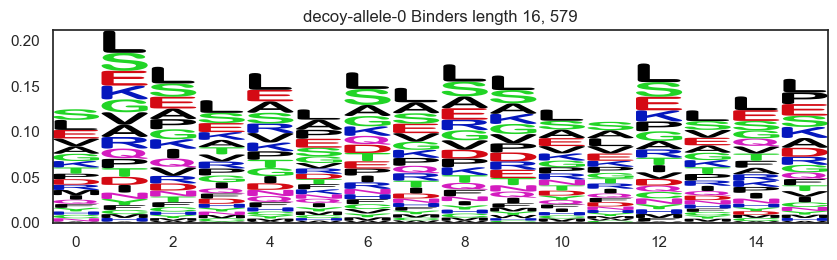

In [19]:
target_length = 16
peptides = per_allele_per_kfold_per_length_binders_train[target_allele][0][target_length]
make_logo_for_data(peptides, f"{ target_allele} Binders length {target_length}")

# Transform data

In [20]:
from data_reading_methods import merge_per_allele_sets_into_combination_sets

def transform_data_to_properties_and_join_alleles(per_allele_per_kfold_per_length_binders_train,
                                                  per_allele_per_kfold_per_length_binders_test, ALLELES=ALLELES):
    per_allele_per_kfold_per_length_binders_train_old = per_allele_per_kfold_per_length_binders_train
    per_allele_per_kfold_per_length_binders_test_old = per_allele_per_kfold_per_length_binders_test

    if check_peptides:
        transform_dicts=None
    per_allele_per_kfold_per_length_binders_train, per_allele_per_kfold_per_length_binders_test = merge_per_allele_sets_into_combination_sets(
        per_allele_per_kfold_per_length_binders_train, per_allele_per_kfold_per_length_binders_test,
        combination_size=combination_size,
        selected_alelles=ALLELES,
        total_splits=TOTAL_SPLITS,
        list_of_transform_dicts=None,position_component=params['position_component']
    )
    OLD_ALLELES = ALLELES
    NEW_ALLELES = list(per_allele_per_kfold_per_length_binders_test.keys())
    ALLELES = NEW_ALLELES
    return per_allele_per_kfold_per_length_binders_train,  \
           per_allele_per_kfold_per_length_binders_test, ALLELES, \
           per_allele_per_kfold_per_length_binders_train_old, \
           per_allele_per_kfold_per_length_binders_test_old, \
           OLD_ALLELES




In [21]:
train_data, \
test_data, \
ALLELES, \
old_train_data, \
old_test_data, \
OLD_ALLELES, \
= transform_data_to_properties_and_join_alleles(
    per_allele_per_kfold_per_length_binders_train,
    per_allele_per_kfold_per_length_binders_test
)

decoy-allele-0
Length 16: decoy-allele-0 - 579 
Length 17: decoy-allele-0 - 580 
Length 18: decoy-allele-0 - 552 
Length 12: decoy-allele-0 - 542 
Length 13: decoy-allele-0 - 548 
Length 14: decoy-allele-0 - 572 
Length 15: decoy-allele-0 - 548 
decoy-allele-194
Length 16: decoy-allele-194 - 576 
Length 17: decoy-allele-194 - 577 
Length 18: decoy-allele-194 - 548 
Length 12: decoy-allele-194 - 570 
Length 13: decoy-allele-194 - 591 
Length 14: decoy-allele-194 - 550 
Length 15: decoy-allele-194 - 596 
decoy-allele-215
Length 16: decoy-allele-215 - 593 
Length 17: decoy-allele-215 - 556 
Length 18: decoy-allele-215 - 548 
Length 12: decoy-allele-215 - 587 
Length 13: decoy-allele-215 - 568 
Length 14: decoy-allele-215 - 554 
Length 15: decoy-allele-215 - 561 
decoy-allele-53
Length 16: decoy-allele-53 - 580 
Length 17: decoy-allele-53 - 566 
Length 18: decoy-allele-53 - 584 
Length 12: decoy-allele-53 - 585 
Length 13: decoy-allele-53 - 568 
Length 14: decoy-allele-53 - 592 
Length 15:

## 2.2 Calculate counts of initial data (will be used to calculate weights further)

In [22]:
from data_reading_methods import extract_count_df, calculate_weights_based_on_length_counts

def get_weights(old_train_data):
    count_df_train = extract_count_df(old_train_data,
                                      selected_alleles=OLD_ALLELES,
                                      total_splits=TOTAL_SPLITS)
    # count_df_test = extract_count_df(old_test_data,
    #                                  selected_alleles=OLD_ALLELES,
    #                                  total_splits=TOTAL_SPLITS)
    # sub_count_df_train = count_df_train.loc[(count_df_train.index.get_level_values('split') == 0) &
    #                                     (count_df_train.index.get_level_values('allele').isin(ALLELES)) &
    #                                     (count_df_train.index.get_level_values('length').isin(TARGET_LENGTHS))]
    #per_allele_per_kfold_per_length_weights
    train_data_weigths =  calculate_weights_based_on_length_counts(count_df_train,
                                                                   selected_alleles=ALLELES,
                                                                   total_splits=TOTAL_SPLITS,
                                                                   selected_lengths=TARGET_LENGTHS,
                                                                   use_weights=USE_WEIGHTS)
    return train_data_weigths


## 2.3 Weights for data based on counts

In [23]:
train_data_weights = get_weights(old_train_data)

Total data length for split 0 is 3921
Weights for lentgh 12 are {'decoy-allele-0': 1}
Weights for lentgh 13 are {'decoy-allele-0': 1}
Weights for lentgh 14 are {'decoy-allele-0': 1}
Weights for lentgh 15 are {'decoy-allele-0': 1}
Weights for lentgh 16 are {'decoy-allele-0': 1}
Weights for lentgh 17 are {'decoy-allele-0': 1}
Weights for lentgh 18 are {'decoy-allele-0': 1}
Devide by 1
Combination decoy-allele-0, split 0: {12: array([1.]), 13: array([1.]), 14: array([1.]), 15: array([1.]), 16: array([1.]), 17: array([1.]), 18: array([1.])}
Total data length for split 1 is 3921
Weights for lentgh 12 are {'decoy-allele-0': 1}
Weights for lentgh 13 are {'decoy-allele-0': 1}
Weights for lentgh 14 are {'decoy-allele-0': 1}
Weights for lentgh 15 are {'decoy-allele-0': 1}
Weights for lentgh 16 are {'decoy-allele-0': 1}
Weights for lentgh 17 are {'decoy-allele-0': 1}
Weights for lentgh 18 are {'decoy-allele-0': 1}
Devide by 1
Combination decoy-allele-0, split 1: {12: array([1.]), 13: array([1.]),

# 2. Train HMMS
## 2.1 Code for HMM
### 2.1.1 Training code+

In [24]:
from hmm_logic_methods import train_model_prepared,  train_model_batched, save_model, add_more_states_and_reset_transitions, init_grouped_structure_model_joiners_and_cycles_here



C:\Users\denkl\AppData\Roaming\Python\Python39\site-packages\tqdm\auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


## 2.2 Train
### 2.2.1 Define treshold

In [25]:
stop_threshold = 0
cutoff = 0.00005
per_symbol_portion = -5
for target_length in TARGET_LENGTHS:
    target_length_for_training = target_length
    train_size = len(per_allele_per_kfold_per_length_binders_train[ALLELES[0]][0][target_length])
    ## Stop threshold Hardcoded here
    stop_threshold +=  abs(cutoff * train_size * per_symbol_portion  * target_length_for_training)
stop_threshold = stop_threshold / len(TARGET_LENGTHS)

params['stop_threshold'] = stop_threshold

stop_threshold

2.104142857142857

### 2.2.2 Prepare  initial grouped structure models

In [26]:
prepared_model = init_grouped_structure_model_joiners_and_cycles_here(
    states_per_group=int(params['states_per_group']),
    number_of_groups=params['groups'],
    IN_CYCLE_TR_PSEUDOCOUNT=params['in_cycle_tr_pseudocount'],
    freeze_distr=params['freeze_distr'],
    initial_params=initial_params,
    start_cycle=params['start_cycle'],
    end_cycle=params['end_cycle'],
    self_cycles=params['self_cycle'],
    cycle_max_components=params['cycle_top_aas'],
    cycle_default_pseudocount=params['cycle_default_pseudocount'],
    discrete_distribution=check_peptides,
    equal_probs_for_cycle=params['equal_probs_for_cycle'],
    tie_cycle_states=params['tie_cycle_states'],
    anchor_max_components=params['anchor_top_aas'],
    anchor_states=params['anchor_states'],
    model_complexity=params['model_complexity'],
    anchor_default_pseudocount= params['anchor_default_pseudocount'],
    tie_anchor_states=params['tie_anchor_states'],
                    intermediate_cycles=params['intermediate_cycles'],
                    equal_probs_for_intermediate_cycle=params['equal_probs_for_intermediate_cycle'],
                    tie_intermediate_cycles=params['tie_intermediate_cycles'],
                    freeze_int_cycle_distr=params['freeze_int_cycle_distr'],
    position_component=params['position_component'],
    cycle_chain=params['cycle_chain']

)

start cycles added 1
end cycles added 2
states will be groups:7 + joiners:2 + start/end cycles:2 + int_cycles:0
One more time number of 'cycle' states 1 1
For example start cycle states [9]


In [27]:
from itertools import islice

In [28]:
prepared_model.dense_transition_matrix().shape

(13, 13)

In [29]:
with open('model.png', 'w+') as f:
    prepared_model.plot(file=f, crop_zero=True, rotation=90, rotate=90)

In [30]:
from hmm_visualization_methods import *
plot_distributions_for_states(prepared_model,"test/", horizontal=False, discrete=check_peptides, initial_params=initial_params)

In [31]:

make_pyviz_graph(prepared_model, "test/", precision=3)

Converting graph for model (grouped_model) (Delete zero edges)


<class 'pyvis.network.Network'> |N|=13 |E|=16

In [32]:
peptide = per_allele_per_kfold_per_length_binders_train[ALLELES[0]][0][18][0]

## Prepare models

In [33]:
def prepare_all_models(RUN_START=0, NUM_RUNS=20, DECREASE_ANCHOR_ACIDS=1):
    ORIGINAL_RUNS = NUM_RUNS
    NUM_RUNS = NUM_RUNS * DECREASE_ANCHOR_ACIDS
    per_allele_per_run_per_split_prepared_models = dict()
    for allele_name in ALLELES:
        target_allele_name = allele_name.replace('-', '_').replace('*', '_').replace(':', '_').replace('/', '_')
        per_allele_per_run_per_split_prepared_models[allele_name] = dict()
        for run_num in range(RUN_START, RUN_START+NUM_RUNS):
            per_allele_per_run_per_split_prepared_models[allele_name][run_num] = dict()
            for split_num in range(TOTAL_SPLITS):
                additional_anchor_acid = (run_num-RUN_START)// ORIGINAL_RUNS
                # prepared_model  = init_grouped_structure_model(states_per_group=int(params['st']/params['groups']), number_of_groups=params['groups'])
                prepared_model = init_grouped_structure_model_joiners_and_cycles_here(
                    states_per_group=int(params['states_per_group']),
                    number_of_groups=params['groups'],
                    IN_CYCLE_TR_PSEUDOCOUNT=params['in_cycle_tr_pseudocount'],
                    freeze_distr=params['freeze_distr'],
                    initial_params=initial_params,
                    start_cycle=params['start_cycle'],
                    end_cycle=params['end_cycle'],
                    self_cycles=params['self_cycle'],
                    discrete_distribution=check_peptides,
                    equal_probs_for_cycle=params['equal_probs_for_cycle'],
                    tie_cycle_states=params['tie_cycle_states'],
                     model_complexity=params['model_complexity'],
                         anchor_default_pseudocount= params['anchor_default_pseudocount'] ,
                 anchor_max_components=params['anchor_top_aas'] - additional_anchor_acid,
                    anchor_states=params['anchor_states'],
                       tie_anchor_states=params['tie_anchor_states'],
                        intermediate_cycles=params['intermediate_cycles'],
                        equal_probs_for_intermediate_cycle=params['equal_probs_for_intermediate_cycle'],
                        tie_intermediate_cycles=params['tie_intermediate_cycles'],
                        freeze_int_cycle_distr=params['freeze_int_cycle_distr'],
                    position_component=params['position_component'],
        cycle_chain=params['cycle_chain'],
                )
                prepared_model.name = f'{run_num}_run-{lengths_string}-{params_string}_model-{target_allele_name}-{split_num}'
                per_allele_per_run_per_split_prepared_models[allele_name][run_num][split_num] = prepared_model
    return per_allele_per_run_per_split_prepared_models

In [34]:
NUM_RUNS, TOTAL_SPLITS

(8, 5)

In [35]:
per_allele_per_run_per_split_prepared_models = prepare_all_models(NUM_RUNS=NUM_RUNS, DECREASE_ANCHOR_ACIDS=2)

start cycles added 1
end cycles added 2
states will be groups:7 + joiners:2 + start/end cycles:2 + int_cycles:0
One more time number of 'cycle' states 1 1
For example start cycle states [9]
start cycles added 1
end cycles added 2
states will be groups:7 + joiners:2 + start/end cycles:2 + int_cycles:0
One more time number of 'cycle' states 1 1
For example start cycle states [9]
start cycles added 1
end cycles added 2
states will be groups:7 + joiners:2 + start/end cycles:2 + int_cycles:0
One more time number of 'cycle' states 1 1
For example start cycle states [9]
start cycles added 1
end cycles added 2
states will be groups:7 + joiners:2 + start/end cycles:2 + int_cycles:0
One more time number of 'cycle' states 1 1
For example start cycle states [9]
start cycles added 1
end cycles added 2
states will be groups:7 + joiners:2 + start/end cycles:2 + int_cycles:0
One more time number of 'cycle' states 1 1
For example start cycle states [9]
start cycles added 1
end cycles added 2
states wil

# Do training

In [36]:
def train_all_models(prepared_models,
                     train_data,
                     test_data,
                     train_data_weights,
                     save_dir= TARGET_PATH_TO_RESULTS,
                     ):
    per_name_models = dict()
    per_name_histories = dict()
    result_histories = dict()
    result_models = dict()
    for allele_name in ALLELES:
        result_histories[allele_name] = dict()
        result_models[allele_name] = dict()
        for run_num in prepared_models[allele_name].keys():
            print(f"run {run_num}")
            per_kfold_per_length_data = train_data[allele_name]
            per_kfold_per_length_weights = train_data_weights[allele_name]

            models, histories = train_model_prepared(
                                            per_kfold_per_length_data=per_kfold_per_length_data,
                                            per_kfold_per_length_weights_for_data=per_kfold_per_length_weights,
                                            target_lengths=TARGET_LENGTHS,
                                            multiple_check_input=params['multiple_check_input'],
                                            algorithm=params['alg'],
                                            verbose=params['verbose'],
                                            per_kfold_per_length_test_data=test_data[allele_name],
                                            stop_threshold=params['stop_threshold'],
                                            min_iterations= params['min_iters'],
                                            max_iterations=params['max_iters'],
                                            prepared_models=prepared_models[allele_name][run_num],
                                            emission_pseudocount=params['emission_pseudocount'],
                                            transition_pseudocount=params['transition_pseudocount'],
                                            edge_inertia=params['edge_inertia'],
                                            distribution_inertia=params['distribution_inertia'],
                                            lr_decay=params['lr_decay'],
                                            use_pseudocount=params['use_pseudocount'],
                                            minibatch_training=params['minibatch_training'],
                                            batches_per_epoch=params['batches_per_epoch'],
                                              batch_size=params['batch_size'],
                                           n_jobs=1)

            result_models[allele_name][run_num] = models
            result_histories[allele_name][run_num] = histories
            # per_allele_per_run_per_split_models[allele_name][run_num] = models
            for split_num, model in models.items():
                per_name_models[model.name] = model
            # save models
            for split_num, model in models.items():
                history = histories[split_num]
                save_model(save_dir, model,history)
    return result_models,\
           result_histories




In [37]:
%%time
TOTAL_SPLITS = 1
result_models, \
result_histories = train_all_models(train_data=train_data,
                                  test_data=test_data,
                                  train_data_weights=train_data_weights,
                                  save_dir=TARGET_PATH_TO_RESULTS,
                                  prepared_models=per_allele_per_run_per_split_prepared_models
                                                              )

run 0
split 0
train size 3921
Shuffling for fairness 
data shuffled
Example of data ['A', 'R', 'E', 'K', 'M', 'A', 'D', 'I', 'Y', 'L', 'K', 'H', 'R', 'K', 'D', 'K', 'M', 'L']
Mini_batch: Train Length 3921, batch_size 1, batches_per_epoch 100
Example of batch (array([list(['A', 'R', 'E', 'K', 'M', 'A', 'D', 'I', 'Y', 'L', 'K', 'H', 'R', 'K', 'D', 'K', 'M', 'L'])],
      dtype=object), array([1.]))
Use pseudocount is True
run 1
split 0
train size 3921
Shuffling for fairness 
data shuffled
Example of data ['T', 'D', 'A', 'I', 'S', 'G', 'L', 'G', 'K', 'E', 'C', 'A']
Mini_batch: Train Length 3921, batch_size 1, batches_per_epoch 100
Example of batch (array([list(['T', 'D', 'A', 'I', 'S', 'G', 'L', 'G', 'K', 'E', 'C', 'A'])],
      dtype=object), array([1.]))
Use pseudocount is True
run 2
split 0
train size 3921
Shuffling for fairness 
data shuffled
Example of data ['F', 'S', 'T', 'K', 'C', 'H', 'G', 'C', 'D', 'F', 'P', 'V', 'E']
Mini_batch: Train Length 3921, batch_size 1, batches_per_epoch

In [38]:
def reorder_models_by_score(histories, models):
    # Sort by score
    per_name_new_models = dict()
    per_name_histories = dict()
    per_split_allele_original_sortings = dict()
    for split_num in range(TOTAL_SPLITS):
        per_split_allele_original_sortings[split_num] = dict()
        for allele_name in ALLELES:
            original_runs = models[allele_name].keys()
            df = pd.DataFrame({"model": original_runs,
                              "log_probability": [histories[allele_name][i][split_num].log_probabilities[-1]
                                                 for i in original_runs],
                             # "test_log_probability":  [per_allele_per_run_per_split_new_histories[allele_name][i][split_num].test_log_probability[-1]
                              #                   for i in range(NUM_RUNS)]
                              })
            df = df.sort_values(by='log_probability', ascending = False).reset_index(drop=True)
            per_split_allele_original_sortings[split_num][allele_name] = df
            original_indexes = original_runs
            for new_index, model_run_num in zip(sorted(original_indexes), df.model):
                original_model =  models[allele_name][model_run_num][split_num]
                original_history = histories[allele_name][model_run_num][split_num]
                original_model_name = original_model.name
                rest_part = original_model_name.split("_", 1)[1]
                new_name = f"{new_index}_{rest_part}"
                original_model.name = new_name
                per_name_new_models[new_name] = original_model
                per_name_histories[new_name] = original_history
    per_name_models = per_name_new_models
    for name, model in per_name_models.items():
        history = per_name_histories[name]
        save_model(TARGET_PATH_TO_RESULTS, model,history)
    return per_name_models, per_name_histories, per_split_allele_original_sortings



In [39]:
per_name_models, per_name_histories, original_alelle_sortings = reorder_models_by_score(histories=result_histories,
                                                                models=result_models)


## Read all the models and save visualizations

In [17]:
from hmm_logic_methods import load_model
EXPERIMENT_NAME_TO_READ = 'multiple_single_allele_models'
TARGET_PATH_TO_RESULTS = f"experiment_results/{EXPERIMENT_NAME_TO_READ}/" #!CHANGE for bwv!
check_peptides = True
initial_params = None

In [18]:
import os
import matplotlib.pyplot as plt

In [19]:
models_to_read = os.listdir(TARGET_PATH_TO_RESULTS)

In [20]:
per_name_models = {model_name: load_model(TARGET_PATH_TO_RESULTS, model_name) for model_name in models_to_read}

In [81]:
from hmm_visualization_methods import *
def save_all_visualization_results(per_name_models, per_name_histories=None,
                                   save_dir=TARGET_PATH_TO_RESULTS,
                                   model_graph=False):

    #learning curve
    if per_name_histories:
        fig, ax = plt.subplots(1, 1)
        for i in range(1):
            sns.lineplot(
                per_name_histories[
                    list(per_name_histories.keys())[i]
                ].log_probabilities, ax=ax)
    if (model_graph):
        print('\nModelGraph')
        for i, model in enumerate(per_name_models.values()):
            print(i, end=' ')
            # with open(f"{TARGET_PATH_TO_RESULTS}{model.name}/state_graph.png", 'w+') as f:
            #     model.plot(file=f, crop_zero=False)
            with open(f"{save_dir}{model.name}/state_graph_cropped.png", 'w+') as f:
                model.plot(file=f, crop_zero=True)
    print('\nDistributions')
    for i, model in enumerate(per_name_models.values()):
        print(i, end=' ')
        plot_distributions_for_states(model,save_dir, horizontal=False, discrete=check_peptides, initial_params=initial_params)

    print('\nPyViz')
    per_name_pyviz = dict()
    for name, model in per_name_models.items():
        per_name_pyviz[name] = make_pyviz_graph(model, save_dir, precision=3)



In [82]:
save_all_visualization_results(per_name_models)


Distributions
0 1 2 3 4 5 6 7 8 9 10 11 12 13 14 15 16 17 18 19 20 21 22 23 24 25 26 27 28 29 30 31 32 33 34 35 36 37 38 39 40 41 42 43 44 45 46 47 48 49 50 51 52 53 54 55 56 57 58 59 
PyViz
Converting graph for model (0_run-12-13-14-15-16-17-18-viterbi-alg-50-min_iters-7-st_model-dummy_allele-0) (Delete zero edges)
Converting graph for model (1_run-12-13-14-15-16-17-18-viterbi-alg-50-min_iters-7-st_model-dummy_allele-0) (Delete zero edges)
Converting graph for model (2_run-12-13-14-15-16-17-18-viterbi-alg-50-min_iters-7-st_model-dummy_allele-0) (Delete zero edges)
Converting graph for model (3_run-12-13-14-15-16-17-18-viterbi-alg-50-min_iters-7-st_model-dummy_allele-0) (Delete zero edges)
Converting graph for model (4_run-12-13-14-15-16-17-18-viterbi-alg-50-min_iters-7-st_model-dummy_allele-0) (Delete zero edges)
Converting graph for model (5_run-12-13-14-15-16-17-18-viterbi-alg-50-min_iters-7-st_model-dummy_allele-0) (Delete zero edges)
Converting graph for model (6_run-12-13-14-15-

# Base models trained. Now we want to estimate splits.
##  Try to enrich main motif

### First sort peptides by score and visualize probability

In [ ]:
import importlib
import hmm_logic_methods
import hmm_visualization_methods
hmm_logic_methods= importlib.reload(hmm_logic_methods)
hmm_visualization_methods= importlib.reload(hmm_visualization_methods)
from hmm_logic_methods import get_all_scores_and_sort_by_best
from hmm_visualization_methods import plot_all_scores_as_lines, plot_all_scores_as_separate_lines, plot_split_diagnostics

In [ ]:
per_allele_data_df = get_all_scores_and_sort_by_best(train_data, per_name_models)


In [ ]:
target_df = plot_all_scores_as_lines(per_allele_data_df, per_name_models)

In [ ]:
plot_all_scores_as_separate_lines(per_allele_data_df, per_name_models)


In [ ]:
t = plot_split_diagnostics(per_allele_data_df, additional)

## Split code

In [ ]:
import math

In [ ]:
# def split_model(per_name_models, train_data, iteration, split_type = 0.5, original_model_index=0):
#     ####!!!! TODO: change to per allele model
#    # selected_model = get_average_model_for_runs(per_name_models)
#     selected_model = per_name_models[list(per_name_models.keys())[original_model_index]]
#     ####!!!
#     per_allele_list_of_dfs = defaultdict(list)
#     for allele_name in ALLELES:
#         for current_split in range(TOTAL_SPLITS):
#             for current_length in TARGET_LENGTHS:
#                 peptides = train_data[allele_name][current_split][current_length]
#                 df = pd.DataFrame({'peptide': peptides,'split': current_split, 'length':current_length})
#                 per_allele_list_of_dfs[allele_name].append(df)
#
#     per_allele_data_df = dict()
#     per_allele_first_df = dict()
#     per_allele_second_df =dict()
#     for allele_name in ALLELES:
#         df = pd.concat(per_allele_list_of_dfs[allele_name])
#         df['score'] = [selected_model.log_probability(peptide)/len(peptide) for peptide in df.peptide]
#         df = df.sort_values(by='score', ascending=False)
#         #df1 = df.loc[df.score > -3].copy()
#         #df2 = df[~df.apply(tuple,axis=1).isin(df1.apply(tuple,axis=1))].copy()
#         #df1 = df[df['score'] >= df['score'].max() - np.log(2)].copy()
#         #df2 = df[df['score'] < df['score'].max() - np.log(2)].copy()
#         df1 = df[df['score'] >= df['score'].mean()].copy()
#         df2 = df[df['score'] < df['score'].mean()].copy()
#         per_allele_first_df[allele_name] = df1
#         per_allele_second_df[allele_name] = df2
#         per_allele_data_df[allele_name] = df
#     new_train_data1 = split_to_dicts(per_allele_first_df, ALLELES, TARGET_LENGTHS, TOTAL_SPLITS)
#     new_train_data2 = split_to_dicts(per_allele_second_df, ALLELES, TARGET_LENGTHS, TOTAL_SPLITS)
#     train_data_weights1 = get_weights(new_train_data1)
#     train_data_weights2 = get_weights(new_train_data2)
#     per_allele_per_run_per_split_prepared_models1 = prepare_all_models()
#     per_allele_per_run_per_split_prepared_models2 = prepare_all_models()
#
#     #1
#     per_allele_per_run_per_split_prepared_models1, \
#     per_allele_per_run_per_split_new_histories1 = train_all_models(train_data=new_train_data1,
#                                                                   test_data=test_data,
#                                                                   train_data_weights=train_data_weights1,
#                                                                   save_dir=TARGET_PATH_TO_RESULTS + f'/new_model{iteration}1/',
#                                                                   prepared_models=per_allele_per_run_per_split_prepared_models1
#                                                                   )
#     #2
#     per_allele_per_run_per_split_prepared_models2, \
#     per_allele_per_run_per_split_new_histories2 = train_all_models(train_data=new_train_data2,
#                                                                   test_data=test_data,
#                                                                   train_data_weights=train_data_weights2,
#                                                                   save_dir=TARGET_PATH_TO_RESULTS +f'/new_model{iteration}2/',
#                                                                   prepared_models=per_allele_per_run_per_split_prepared_models2
#                                                                   )
#     per_name_models1, per_name_histories1 = reorder_models_by_score(histories=per_allele_per_run_per_split_new_histories1,
#                                                                 models=per_allele_per_run_per_split_prepared_models1)
#     per_name_models2, per_name_histories2 = reorder_models_by_score(histories=per_allele_per_run_per_split_new_histories2,
#                                                                     models=per_allele_per_run_per_split_prepared_models2)
#     save_all_visualization_results(per_name_models1, per_name_histories1, save_dir=TARGET_PATH_TO_RESULTS + f'/new_model{iteration}1/')
#     save_all_visualization_results(per_name_models2, per_name_histories2, save_dir=TARGET_PATH_TO_RESULTS + f'/new_model{iteration}2/')
#
#     return per_name_models1, per_name_models2, new_train_data1, new_train_data2





## Make all splits

In [ ]:
NUM_RUNS = 8
NUM_RUNS

In [ ]:
from data_reading_methods import split_to_dicts

def split_model_and_enrich(per_name_models, train_data, iteration,
                           split_type = 0.5,
                           original_model_index=0,
                           enrichment_steps = 3,
                           NUM_RUNS =20,
                           DECREASE_ANCHOR_ACIDS_STEPS = 1,
                           model_index_start=0):
    ####!!!! TODO: change to per allele model
   # selected_model = get_average_model_for_runs(per_name_models)
    selected_model = per_name_models[list(per_name_models.keys())[original_model_index]]
    ####!!!
    per_allele_list_of_dfs = defaultdict(list)
    for allele_name in ALLELES:
        for current_split in range(TOTAL_SPLITS):
            for current_length in TARGET_LENGTHS:
                peptides = train_data[allele_name][current_split][current_length]
                df = pd.DataFrame({'peptide': peptides,'split': current_split, 'length':current_length})
                per_allele_list_of_dfs[allele_name].append(df)

    per_allele_data_df = dict()
    per_allele_first_df = dict()
    per_allele_second_df =dict()
    for allele_name in ALLELES:
        df = pd.concat(per_allele_list_of_dfs[allele_name])
        df['score'] = [selected_model.log_probability(peptide)/len(peptide) for peptide in df.peptide]
        df = df.sort_values(by='score', ascending=False)
        #df1 = df.loc[df.score > -3].copy()
        #df2 = df[~df.apply(tuple,axis=1).isin(df1.apply(tuple,axis=1))].copy()
        #df1 = df[df['score'] >= df['score'].max() - np.log(2)].copy()
        #df2 = df[df['score'] < df['score'].max() - np.log(2)].copy()
        df1 = df[df['score'] >= df['score'].mean()].copy()
        df2 = df[df['score'] < df['score'].mean()].copy()
        per_allele_first_df[allele_name] = df1
        per_allele_second_df[allele_name] = df2
        per_allele_data_df[allele_name] = df
    new_train_data1 = split_to_dicts(per_allele_first_df, ALLELES, TARGET_LENGTHS, TOTAL_SPLITS)
    new_train_data2 = split_to_dicts(per_allele_second_df, ALLELES, TARGET_LENGTHS, TOTAL_SPLITS)
    train_data_weights1 = get_weights(new_train_data1)
    train_data_weights2 = get_weights(new_train_data2)
    per_allele_per_run_per_split_prepared_models1 = prepare_all_models(RUN_START=model_index_start,
                                                                       NUM_RUNS=NUM_RUNS,
                                                                       DECREASE_ANCHOR_ACIDS=DECREASE_ANCHOR_ACIDS_STEPS)
    per_allele_per_run_per_split_prepared_models2 = prepare_all_models(RUN_START=model_index_start + NUM_RUNS*DECREASE_ANCHOR_ACIDS_STEPS,
                                                                       NUM_RUNS=NUM_RUNS,
                                                                       DECREASE_ANCHOR_ACIDS=DECREASE_ANCHOR_ACIDS_STEPS)

    #1
    per_allele_per_run_per_split_prepared_models1, \
    per_allele_per_run_per_split_new_histories1 = train_all_models(train_data=new_train_data1,
                                                                  test_data=test_data,
                                                                  train_data_weights=train_data_weights1,
                                                                  save_dir=TARGET_PATH_TO_RESULTS + f'/new_model{iteration}1/',
                                                                  prepared_models=per_allele_per_run_per_split_prepared_models1
                                                                  )
    #2
    per_allele_per_run_per_split_prepared_models2, \
    per_allele_per_run_per_split_new_histories2 = train_all_models(train_data=new_train_data2,
                                                                  test_data=test_data,
                                                                  train_data_weights=train_data_weights2,
                                                                  save_dir=TARGET_PATH_TO_RESULTS +f'/new_model{iteration}2/',
                                                                  prepared_models=per_allele_per_run_per_split_prepared_models2
                                                                  )
    per_name_models1, per_name_histories1,_ = reorder_models_by_score(histories=per_allele_per_run_per_split_new_histories1,
                                                                models=per_allele_per_run_per_split_prepared_models1)
    per_name_models2, per_name_histories2,_ = reorder_models_by_score(histories=per_allele_per_run_per_split_new_histories2,
                                                                    models=per_allele_per_run_per_split_prepared_models2)

    # ## Here we want to plot UMAP for freshly splited models
    # total_models = dict()
    # total_models.update(per_name_models1)
    # total_models.update(per_name_models2)
    # print(f"length of models is {len(total_models)}" )
    # per_allele_scores_data = get_all_scores_and_sort_by_best(train_data, total_models)
    # plot_split_diagnostics(per_allele_scores_data, additional)



    ## enrichment step
    print("Enrichment")
    for i in range(enrichment_steps):
        print("enrichment iteration", i)
        for allele_name in ALLELES:
            df = per_allele_data_df[allele_name]
            selected_model1 = per_name_models1[list(per_name_models1)[0]]
            selected_model2 = per_name_models2[list(per_name_models2)[0]]
            df[f'score1_step{i}'] = [selected_model1.log_probability(peptide)/len(peptide) for peptide in df.peptide]
            df[f'score2_step{i}'] = [selected_model2.log_probability(peptide)/len(peptide) for peptide in df.peptide]
            df1 = df[df[f'score1_step{i}'] >= df[f'score2_step{i}']].copy()
            df2 = df[df[f'score2_step{i}'] >= df[f'score1_step{i}']].copy()
            per_allele_first_df[allele_name] = df1
            per_allele_second_df[allele_name] = df2
            per_allele_data_df[allele_name] = df
        new_train_data1 = split_to_dicts(per_allele_first_df, ALLELES, TARGET_LENGTHS, TOTAL_SPLITS)
        new_train_data2 = split_to_dicts(per_allele_second_df, ALLELES, TARGET_LENGTHS, TOTAL_SPLITS)
        train_data_weights1 = get_weights(new_train_data1)
        train_data_weights2 = get_weights(new_train_data2)
        per_allele_per_run_per_split_prepared_models1 = prepare_all_models(RUN_START=model_index_start,
                                                                           NUM_RUNS=NUM_RUNS,
                                                                           DECREASE_ANCHOR_ACIDS=DECREASE_ANCHOR_ACIDS_STEPS)
        per_allele_per_run_per_split_prepared_models2 = prepare_all_models(RUN_START=model_index_start + NUM_RUNS*DECREASE_ANCHOR_ACIDS_STEPS,
                                                                           NUM_RUNS=NUM_RUNS,
                                                                           DECREASE_ANCHOR_ACIDS=DECREASE_ANCHOR_ACIDS_STEPS)
         #1
        print(f"Model {iteration}1")
        per_allele_per_run_per_split_prepared_models1, \
        per_allele_per_run_per_split_new_histories1 = train_all_models(train_data=new_train_data1,
                                                                      test_data=test_data,
                                                                      train_data_weights=train_data_weights1,
                                                                      save_dir=TARGET_PATH_TO_RESULTS + f'/new_model{iteration}1/',
                                                                      prepared_models=per_allele_per_run_per_split_prepared_models1
                                                                      )
        #2
        print(f"Model {iteration}2")
        per_allele_per_run_per_split_prepared_models2, \
        per_allele_per_run_per_split_new_histories2 = train_all_models(train_data=new_train_data2,
                                                                      test_data=test_data,
                                                                      train_data_weights=train_data_weights2,
                                                                      save_dir=TARGET_PATH_TO_RESULTS +f'/new_model{iteration}2/',
                                                                      prepared_models=per_allele_per_run_per_split_prepared_models2
                                                                      )
        per_name_models1, per_name_histories1,_ = reorder_models_by_score(histories=per_allele_per_run_per_split_new_histories1,
                                                                    models=per_allele_per_run_per_split_prepared_models1)
        per_name_models2, per_name_histories2,_ = reorder_models_by_score(histories=per_allele_per_run_per_split_new_histories2,
                                                                        models=per_allele_per_run_per_split_prepared_models2)

    save_all_visualization_results(per_name_models1, per_name_histories1, save_dir=TARGET_PATH_TO_RESULTS + f'/new_model{iteration}1/')
    save_all_visualization_results(per_name_models2, per_name_histories2, save_dir=TARGET_PATH_TO_RESULTS + f'/new_model{iteration}2/')

    return per_name_models1, per_name_models2, new_train_data1, new_train_data2, per_allele_data_df


In [ ]:
%%time
from collections import deque
import sys
orig_stdout = sys.stdout
with open('out.txt', 'w') as f:
  #  sys.stdout = f
    # try single split and multiple enrichments
    stats_storage = dict()
    iteration = "1"
    models_deque = deque()
    data_deque = deque()
    iteration_deque = deque()

    models_deque.append(per_name_models)
    data_deque.append(train_data)
    iteration_deque.append("1")

    total_models = dict()

    for i in range(7):
        per_name_current_models = models_deque.popleft()
        this_train_data = data_deque.popleft()
        iteration = iteration_deque.popleft()
        print("iteration", iteration)
        # run current data
        per_name_models1, per_name_models2, new_train_data1, new_train_data2, enrichmenet_stats = split_model_and_enrich(per_name_current_models, this_train_data, iteration, enrichment_steps=3, model_index_start=len(total_models),NUM_RUNS=NUM_RUNS, DECREASE_ANCHOR_ACIDS_STEPS=2 )
        # Add current models to the total representation and visualize UMAP of this representation
        total_models.update(per_name_models1)
        total_models.update(per_name_models2)
        print(f"length of models is {len(total_models)}" )
        per_allele_scores_data = get_all_scores_and_sort_by_best(train_data, total_models)
        plot_split_diagnostics(per_allele_scores_data, additional)

        # add left to queue
        models_deque.append(per_name_models1)
        stats_storage[iteration] = enrichmenet_stats

        #data_deque.append(new_train_data1)
        # add whole train data
        data_deque.append(new_train_data1)
        iteration_deque.append(f'{iteration}1')
        models_deque.append(per_name_models2)
        data_deque.append(new_train_data2)
        # add whole train data
       # data_deque.append(train_data)
        iteration_deque.append(f'{iteration}2')
        if i in {0, 2, 6}:
            params['emission_pseudocount']=  params['emission_pseudocount']/2
        if i in {0, 2, 6}:
            #params['anchor_default_pseudocount']=  params['anchor_default_pseudocount']/2
            #params['anchor_top_aas'] = params['anchor_top_aas'] - 1
            pass
        if i in {0, 2, 6}:
            # make total data df (should be per allele)
            per_allele_list_of_dfs = defaultdict(list)
            for allele_name in ALLELES:
                for current_split in range(TOTAL_SPLITS):
                    for current_length in TARGET_LENGTHS:
                        peptides = train_data[allele_name][current_split][current_length]
                        df = pd.DataFrame({'peptide': peptides,'split': current_split, 'length':current_length})
                        per_allele_list_of_dfs[allele_name].append(df)
            #
            per_allele_X_matrix = dict()
            for allele_name in ALLELES:
                total_data = pd.concat(per_allele_list_of_dfs[allele_name])
                for model_num in range(len(models_deque)):
                    current_models = models_deque[model_num]
                    selected_model = current_models[list(current_models.keys())[0]]
                    total_data[f'score_general_{model_num}'] = [selected_model.log_probability(peptide)/len(peptide) for peptide in total_data.peptide]
                X_matrix = total_data[[f'score_general_{i}' for i in range(len(models_deque))]].copy()
                X_matrix['max_column'] = X_matrix.idxmax(axis=1)
            #
                per_allele_X_matrix[allele_name] = X_matrix
            #
            new_train_data = list()
            for model_num in range(len(models_deque)):
                per_allele_new_df = dict()
                for allele_name in ALLELES:
                    X_matrix = per_allele_X_matrix[allele_name]
                    new_df = total_data[X_matrix['max_column'] == f'score_general_{model_num}'].copy()
                    per_allele_new_df[allele_name] =new_df
                new_train_data = split_to_dicts(per_allele_new_df, ALLELES, TARGET_LENGTHS, TOTAL_SPLITS)
                data_deque[model_num] = new_train_data
                # nor we want to reorder all peptides according to scores of 2-4-6-8
   # sys.stdout = orig_stdout





In [ ]:
per_allele_scores_data = get_all_scores_and_sort_by_best(train_data, total_models)
df = per_allele_scores_data[allele_name]
target_df = df[[col for col in df.columns if col.startswith("model")]]
sns.clustermap(target_df)

In [ ]:
sns.clustermap(target_df, metric="correlation" )



## Analyze stats

In [ ]:
df = per_allele_scores_data[ALLELES[0]]

In [ ]:
pd

In [ ]:
t = dict()
t['model_1x'] = list(df.model_1.values)
t['model_12']= list(df.model_2.values)
t['model_3x'] = list(df.model_3.values)

In [ ]:
pd.concat([df, pd.DataFrame(t, index=df.index )], axis=1)

In [ ]:
df

In [ ]:
df = per_allele_scores_data[allele_name]
target_df = df[[col for col in df.columns if col.startswith("model")]]
sns.clustermap(target_df)
pca = PCA(n_components=30)
pca_result = pca.fit_transform(target_df.values)
ann_df = additional[0][allele_name]
ann_df = ann_df[ann_df.split == 0]
print("this method supports 1 split for now")
ann_df = ann_df[['peptide', 'allele']]
annotated_df = df.merge(ann_df, on='peptide', how='left', validate='1:1')
to_plot = pd.DataFrame({"x": pca_result[:, 1], "y": pca_result[:, 2], "allele":annotated_df.allele.values})
sns.jointplot(to_plot, x="x", y="y", hue="allele", kind='kde')
fit = umap.UMAP()
u = fit.fit_transform(pca_result)
to_plot = pd.DataFrame({"x": u[:, 0], "y": u[:, 1], "allele": annotated_df.allele.values, "peptide": annotated_df.peptide.values})
sns.jointplot(to_plot, x="x", y="y", hue='allele', kind='kde')

In [ ]:
stats_storage.keys()

In [ ]:
enrichmenet_stats = stats_storage["11"]

In [ ]:
df = enrichmenet_stats[ALLELES[0]]

In [ ]:
df1 = df[df['score'] >= df['score'].mean()].copy()
df2 = df[df['score'] < df['score'].mean()].copy()
len(df1), len(df2)

In [ ]:
lengths = list()
for step in range(5):
    #print("Step", step)
    df1 = df[df[f'score1_step{step}'] >= df[f'score2_step{step}']].copy()
    df2 = df[df[f'score2_step{step}'] >= df[f'score1_step{step}']].copy()
    lengths.append(f"{len(df1)}/{len(df2)}")

print(" -> ".join(lengths))

In [ ]:
df = enrichmenet_stats[ALLELES[0]]

current_step = 0
columns = [f"score1_step{current_step}",f"score2_step{current_step}"]
t_df = df.copy()
t_df = t_df.sort_values(by=f"score1_step{current_step}", ascending=False)
t_df = t_df.reset_index(drop=True)
target_df =t_df.melt(id_vars=['peptide'],value_vars=columns, value_name = 'score', var_name='model', ignore_index=False)
ax = sns.lineplot(target_df, x=target_df.index, y=f'score', hue='model', palette=sns.color_palette("husl", 2))
sns.move_legend(ax, "upper left", bbox_to_anchor=(1, 1))


In [ ]:
df = enrichmenet_stats[ALLELES[0]]

current_step = 1
columns = [f"score1_step{current_step}",f"score2_step{current_step}"]
t_df = df.copy()
t_df = t_df.sort_values(by=f"score1_step{current_step}", ascending=False)
t_df = t_df.reset_index(drop=True)
target_df =t_df.melt(id_vars=['peptide'],value_vars=columns, value_name = 'score', var_name='model', ignore_index=False)
ax = sns.lineplot(target_df, x=target_df.index, y=f'score', hue='model', palette=sns.color_palette("husl", 2))
sns.move_legend(ax, "upper left", bbox_to_anchor=(1, 1))

In [ ]:
df = enrichmenet_stats[ALLELES[0]]

current_step = 2
columns = [f"score1_step{current_step}",f"score2_step{current_step}"]
t_df = df.copy()
t_df = t_df.sort_values(by=f"score1_step{current_step}", ascending=False)
t_df = t_df.reset_index(drop=True)
target_df =t_df.melt(id_vars=['peptide'],value_vars=columns, value_name = 'score', var_name='model', ignore_index=False)
ax = sns.lineplot(target_df, x=target_df.index, y=f'score', hue='model', palette=sns.color_palette("husl", 2))
sns.move_legend(ax, "upper left", bbox_to_anchor=(1, 1))


In [ ]:
df = enrichmenet_stats[ALLELES[0]]

current_step = 3
columns = [f"score1_step{current_step}",f"score2_step{current_step}"]
t_df = df.copy()
t_df = t_df.sort_values(by=f"score1_step{current_step}", ascending=False)
t_df = t_df.reset_index(drop=True)
target_df =t_df.melt(id_vars=['peptide'],value_vars=columns, value_name = 'score', var_name='model', ignore_index=False)
ax = sns.lineplot(target_df, x=target_df.index, y=f'score', hue='model', palette=sns.color_palette("husl", 2))
sns.move_legend(ax, "upper left", bbox_to_anchor=(1, 1))


In [ ]:
df = enrichmenet_stats[ALLELES[0]]

current_step = 4
columns = [f"score1_step{current_step}",f"score2_step{current_step}"]
t_df = df.copy()
t_df = t_df.sort_values(by=f"score1_step{current_step}", ascending=False)
t_df = t_df.reset_index(drop=True)
target_df =t_df.melt(id_vars=['peptide'],value_vars=columns, value_name = 'score', var_name='model', ignore_index=False)
ax = sns.lineplot(target_df, x=target_df.index, y=f'score', hue='model', palette=sns.color_palette("husl", 2))
sns.move_legend(ax, "upper left", bbox_to_anchor=(1, 1))

## Make additional splits

In [ ]:
a = [iteration_deque.popleft() for i in range(6)]
m = [models_deque.popleft() for i in range(6)]
d = [data_deque.popleft() for i in range(6)]

In [ ]:
iteration_deque

In [ ]:
per_name_current_models = models_deque.popleft()
this_train_data = data_deque.popleft()
iteration = iteration_deque.popleft()
print("iteration", iteration)
# run current data
per_name_models1, per_name_models2, new_train_data1, new_train_data2, enrichmenet_stats = split_model_and_enrich(per_name_current_models, this_train_data, iteration, enrichment_steps=5)
# add left to queue
models_deque.append(per_name_models1)
stats_storage[iteration] = enrichmenet_stats

#data_deque.append(new_train_data1)
# add whole train data
data_deque.append(new_train_data1)
iteration_deque.append(f'{iteration}1')
models_deque.append(per_name_models2)
data_deque.append(new_train_data2)
# add whole train data
# data_deque.append(train_data)
iteration_deque.append(f'{iteration}2')
if i in {0, 2, 6}:
    #params['anchor_default_pseudocount']=  params['anchor_default_pseudocount']/2
    params['emission_pseudocount']=  params['emission_pseudocount']/2
if i in {0, 2, 6}:
    # make total data df (should be per allele)
    per_allele_list_of_dfs = defaultdict(list)
    for allele_name in ALLELES:
        for current_split in range(TOTAL_SPLITS):
            for current_length in TARGET_LENGTHS:
                peptides = train_data[allele_name][current_split][current_length]
                df = pd.DataFrame({'peptide': peptides,'split': current_split, 'length':current_length})
                per_allele_list_of_dfs[allele_name].append(df)
    #
    per_allele_X_matrix = dict()
    for allele_name in ALLELES:
        total_data = pd.concat(per_allele_list_of_dfs[allele_name])
        for model_num in range(len(models_deque)):
            current_models = models_deque[model_num]
            selected_model = current_models[list(current_models.keys())[0]]
            total_data[f'score_general_{model_num}'] = [selected_model.log_probability(peptide)/len(peptide) for peptide in total_data.peptide]
        X_matrix = total_data[[f'score_general_{i}' for i in range(len(models_deque))]].copy()
        X_matrix['max_column'] = X_matrix.idxmax(axis=1)
    #
        per_allele_X_matrix[allele_name] = X_matrix
    #
    new_train_data = list()
    for model_num in range(len(models_deque)):
        per_allele_new_df = dict()
        for allele_name in ALLELES:
            X_matrix = per_allele_X_matrix[allele_name]
            new_df = total_data[X_matrix['max_column'] == f'score_general_{model_num}'].copy()
            per_allele_new_df[allele_name] =new_df
        new_train_data = split_to_dicts(per_allele_new_df, ALLELES, TARGET_LENGTHS, TOTAL_SPLITS)
        data_deque[model_num] = new_train_data
        # nor we want to reorder all peptides according to scores of 2-4-6-8

In [ ]:
NUM_RUNS = 3

In [ ]:
from collections import deque

# try two splits  and multiple enrichments
stats_storage = dict()
iteration = "1"
models_deque = deque()
data_deque = deque()
iteration_deque = deque()

models_deque.append(per_name_models)
data_deque.append(train_data)
iteration_deque.append("1")

for i in range(3):
    per_name_current_models = models_deque.popleft()
    this_train_data = data_deque.popleft()
    iteration = iteration_deque.popleft()
    # run current data
    per_name_models1, per_name_models2, new_train_data1, new_train_data2, enrichmenet_stats = split_model_and_enrich(per_name_current_models, this_train_data, iteration, enrichment_steps=5)
    # add left to queue
    models_deque.append(per_name_models1)
    stats_storage[iteration] = enrichmenet_stats
    #data_deque.append(new_train_data1)
    # add whole train data
    data_deque.append(new_train_data1)
    iteration_deque.append(f'{iteration}1')
    models_deque.append(per_name_models2)
    data_deque.append(new_train_data2)
    # add whole train data
   # data_deque.append(train_data)
    iteration_deque.append(f'{iteration}2')
    if i in {0, 2, 6}:
        #params['anchor_default_pseudocount']=  params['anchor_default_pseudocount']/2
        params['emission_pseudocount']=  params['emission_pseudocount']/2



In [ ]:
current_step = 3
columns = [f"score1_step{current_step}",f"score2_step{current_step}"]
t_df = df.copy()
t_df = t_df.sort_values(by=f"score1_step{current_step}", ascending=False)
target_df =t_df.melt(id_vars=['peptide'],value_vars=columns, value_name = 'score', var_name='model', ignore_index=False)
ax = sns.lineplot(target_df, x=target_df.index, y=f'score', hue='model', palette=sns.color_palette("husl", 2))
sns.move_legend(ax, "upper left", bbox_to_anchor=(1, 1))

In [ ]:
enrichmenet_stats[ALLELES[0]]

## Make all splits

In [ ]:
for i in range(7):
    per_name_current_models = models_deque.popleft()
    this_train_data = data_deque.popleft()
    iteration = iteration_deque.popleft()
    # run current data
    per_name_models1, per_name_models2, new_train_data1, new_train_data2 = split_model(per_name_current_models, this_train_data, iteration)
    # add left to queue
    models_deque.append(per_name_models1)

    #data_deque.append(new_train_data1)
    # add whole train data
    data_deque.append(new_train_data1)
    iteration_deque.append(f'{iteration}1')
    models_deque.append(per_name_models2)
    data_deque.append(new_train_data2)
    # add whole train data
   # data_deque.append(train_data)
    iteration_deque.append(f'{iteration}2')
    if i in {0, 2, 6}:
        #params['anchor_default_pseudocount']=  params['anchor_default_pseudocount']/2
        params['emission_pseudocount']=  params['emission_pseudocount']/2

In [ ]:
from collections import deque

result_models1 = list()
result_models2 = list()
result_train_data1 = list()
result_train_data2 = list()
iteration = "1"
split_types = [0.05, 0.1, 0.15, 0.2, 0.25, 0.3, 0.35, 0.4, 0.45, 0.5, 0.55, 0.6, 0.65, 0.7, 0.75, 0.8, 0.85, 0.9, 0.95]

for split_type in split_types:
    split_type = round(split_type, 2)
    rest_part = np.round(split_type, 2)
    iteration = f"-({split_type},{rest_part})-"
    #pet_name models is the same base model
    #train_data is the same train data
    per_name_models1, per_name_models2, new_train_data1, new_train_data2 = split_model(per_name_models, train_data, iteration, split_type=split_type)
    result_models1.append(per_name_models1)
    result_models2.append(per_name_models2)
    result_train_data1.append(new_train_data1)
    result_train_data2.append(new_train_data2)


In [ ]:
len(result_models1)

## Show scores for splited models

In [ ]:
def get_average_model_for_runs(per_name_models):
    example_model = per_name_models[list(per_name_models.keys())[0]]
    transition_matrix_cube = np.zeros((NUM_RUNS, len(example_model.states), len(example_model.states)))
    emission_matrix_cube = np.zeros((NUM_RUNS, len(example_model.states)-2, 20))

    for i, model in enumerate(per_name_models.values()):
        transition_matrix_cube[i, :, :] = model.dense_transition_matrix()
        for j,state in enumerate(model.states):
            if state.distribution is not None:
                params = list(state.distribution.parameters[0].values())
                emission_matrix_cube[i, j, :] = np.array(params)

    mean_emission_table = np.median(emission_matrix_cube, axis=0)
    mean_transition_table = np.median(transition_matrix_cube, axis=0)

    distributions = []
    amino_acids_list = list('ACDEFGHIKLMNPQRSTVWY')
    for j in range(len(example_model.states)-2):
        d_dict = {key: prob for key, prob in zip(amino_acids_list, mean_emission_table[j, :])}
        curr_distribution = DiscreteDistribution(d_dict)
        distributions.append(curr_distribution)

    model = HiddenMarkovModel.from_matrix(
        name="average model",
        transition_probabilities=mean_transition_table[:-2,:-2],
        starts=mean_transition_table[-2, :],
        distributions=distributions,
        ends=mean_transition_table[:, -1],
        state_names = ["s{:03d}".format(i) for i in range(len(example_model.states)-2)],
        verbose=True)
    model.bake()
    return model

In [ ]:
per_allele_list_of_dfs = defaultdict(list)

for allele_name in ALLELES:
    for current_split in range(TOTAL_SPLITS):
        for current_length in TARGET_LENGTHS:
            peptides = train_data[allele_name][current_split][current_length]
            df = pd.DataFrame({'peptide': peptides,'split': current_split, 'length':current_length})
            per_allele_list_of_dfs[allele_name].append(df)

per_allele_data_df = dict()
for allele_name in ALLELES:
    per_allele_data_df[allele_name] = pd.concat(per_allele_list_of_dfs[allele_name])
for allele_name in ALLELES:
    df = per_allele_data_df[allele_name]
    for i, model in enumerate(per_name_models.values()):
        df[f'model_{i}'] = [model.log_probability(peptide)/len(peptide) for peptide in df.peptide]
        df = df.sort_values(by='model_0', ascending=False)
        per_allele_data_df[allele_name] = df

In [ ]:
for allele_name in ALLELES:
    df = per_allele_data_df[allele_name]
    for current_split, models_dict in zip(split_types,result_models1):
        selected_model = get_average_model_for_runs(models_dict)
        df[f'model_{current_split}'] = [selected_model.log_probability(peptide)/len(peptide) for peptide in df.peptide]
        per_allele_data_df[allele_name] = df

In [ ]:
per_allele_data_df[allele_name]

In [ ]:
df = df.reset_index(drop=True)
target_df =df.melt(id_vars=['peptide'],value_vars=['model_0'] + [f'model_{i}' for i in split_types], value_name = 'score', var_name='model', ignore_index=False)

In [ ]:
for allele_name in ALLELES:
    df = per_allele_data_df[allele_name]
    for current_split, models_dict in zip(split_types,result_models2):
        selected_model = get_average_model_for_runs(models_dict)
        df[f'model_{current_split}_alt'] = [selected_model.log_probability(peptide)/len(peptide) for peptide in df.peptide]
        per_allele_data_df[allele_name] = df

In [ ]:
per_allele_data_df[allele_name]
df = df.reset_index(drop=True)
target_df = df.melt(id_vars=['peptide'], value_vars=['model_0'] + [f'model_{i}_alt' for i in split_types],
                    value_name='score', var_name='model', ignore_index=False)

In [ ]:
target_df

In [ ]:
df

In [ ]:
ax = sns.lineplot(target_df, x=target_df.index, y=f'score', hue='model')
sns.move_legend(ax, "upper left", bbox_to_anchor=(1, 1))


In [ ]:
target_model = 0.7
new_df = df.sort_values(by=f'model_0', ascending=False)
new_df = new_df.reset_index(drop=True)
target_df = new_df.melt(id_vars=['peptide'], value_vars=['model_0'] + [f'model_{i}_alt' for i in [ target_model]] + [f'model_{i}' for i in [target_model]],
                    value_name='score', var_name='model', ignore_index=False)
ax = sns.lineplot(target_df, x=target_df.index, y=f'score', hue='model')
sns.move_legend(ax, "upper left", bbox_to_anchor=(1, 1))

# Calculate scores for dataset

In [ ]:
def get_average_model_for_runs(per_name_models):
    example_model = per_name_models[list(per_name_models.keys())[0]]
    transition_matrix_cube = np.zeros((NUM_RUNS, len(example_model.states), len(example_model.states)))
    emission_matrix_cube = np.zeros((NUM_RUNS, len(example_model.states)-2, 20))

    for i, model in enumerate(per_name_models.values()):
        transition_matrix_cube[i, :, :] = model.dense_transition_matrix()
        for j,state in enumerate(model.states):
            if state.distribution is not None:
                params = list(state.distribution.parameters[0].values())
                emission_matrix_cube[i, j, :] = np.array(params)

    mean_emission_table = np.median(emission_matrix_cube, axis=0)
    mean_transition_table = np.median(transition_matrix_cube, axis=0)

    distributions = []
    amino_acids_list = list('ACDEFGHIKLMNPQRSTVWY')
    for j in range(len(example_model.states)-2):
        d_dict = {key: prob for key, prob in zip(amino_acids_list, mean_emission_table[j, :])}
        curr_distribution = DiscreteDistribution(d_dict)
        distributions.append(curr_distribution)

    model = HiddenMarkovModel.from_matrix(
        name="average model",
        transition_probabilities=mean_transition_table[:-2,:-2],
        starts=mean_transition_table[-2, :],
        distributions=distributions,
        ends=mean_transition_table[:, -1],
        state_names = ["s{:03d}".format(i) for i in range(len(example_model.states)-2)],
        verbose=True)
    model.bake()
    return model

In [ ]:
selected_model = get_average_model_for_runs(per_name_models)

In [ ]:
per_allele_list_of_dfs = defaultdict(list)

for allele_name in ALLELES:
    for current_split in range(TOTAL_SPLITS):
        for current_length in TARGET_LENGTHS:
            peptides = train_data[allele_name][current_split][current_length]
            df = pd.DataFrame({'peptide': peptides,'split': current_split, 'length':current_length})
            per_allele_list_of_dfs[allele_name].append(df)

per_allele_data_df = dict()
for allele_name in ALLELES:
    per_allele_data_df[allele_name] = pd.concat(per_allele_list_of_dfs[allele_name])

In [ ]:
per_allele_data_df[ALLELES[0]]

In [ ]:
for allele_name in ALLELES:
    df = per_allele_data_df[allele_name]
    df['score'] = [selected_model.log_probability(peptide)/len(peptide) for peptide in df.peptide]
    df = df.sort_values(by='score', ascending=False)
    per_allele_data_df[allele_name] = df

In [ ]:
df

In [ ]:
df[df.score > -3].length.value_counts()

In [ ]:
df1 = df.loc[df.score > -3].copy()
df2 = df[~df.apply(tuple,axis=1).isin(df1.apply(tuple,axis=1))].copy()

In [ ]:
df1

In [ ]:
df[df.index.isin(df1.index)]

In [ ]:
per_allele_data_df[allele_name].to_csv('original_predictions.csv', sep=';')

# Get top 50% in one dataset another top 50% in another

In [ ]:
import seaborn as sns

In [ ]:
per_allele_first_df = dict()
per_allele_second_df = dict()
for allele_name in ALLELES:
    df = per_allele_data_df[allele_name]
    df['score'] = [selected_model.log_probability(peptide)/len(peptide) for peptide in df.peptide]
    df = df.sort_values(by='score', ascending=False)
    df1 = df.iloc[:int(len(df)/2)].copy()
    df2 = df.iloc[int(len(df)/2):].copy()
    per_allele_first_df[allele_name] = df1
    per_allele_second_df[allele_name] = df2
    per_allele_data_df[allele_name] = df

In [ ]:
sns.displot(df, x='score')

## Iterations of such procedure

In [ ]:
len(train_data[ALLELES[0]][0][15])

## Train models for different splits based on single one

In [ ]:
from collections import deque

iteration = "1"
split_types = np.linspace(0.05, 0.95, num=20)


for split_type in split_types:
    split_type = round(split_type, 2)
    rest_part =round(1-split_type, 2)
    iteration = f"-({split_type},{rest_part})-"
    #pet_name models is the same base model
    #train_data is the same train data
    per_name_models1, per_name_models2, new_train_data1, new_train_data2 = split_model(per_name_models, train_data, iteration, split_type=split_type)


In [ ]:
split_type = round(split_types[2], 2)
iteration = f"-({split_type},{1-split_type})-"

In [ ]:
split_type

In [ ]:
####!!!! TODO: change to per allele model
# selected_model = get_average_model_for_runs(per_name_models)
selected_model = per_name_models[list(per_name_models.keys())[0]]
####!!!
per_allele_list_of_dfs = defaultdict(list)
for allele_name in ALLELES:
    for current_split in range(TOTAL_SPLITS):
        for current_length in TARGET_LENGTHS:
            peptides = train_data[allele_name][current_split][current_length]
            df = pd.DataFrame({'peptide': peptides,'split': current_split, 'length':current_length})
            per_allele_list_of_dfs[allele_name].append(df)

per_allele_data_df = dict()
per_allele_first_df = dict()
per_allele_second_df =dict()
for allele_name in ALLELES:
    df = pd.concat(per_allele_list_of_dfs[allele_name])
    df['score'] = [selected_model.log_probability(peptide)/len(peptide) for peptide in df.peptide]
    df = df.sort_values(by='score', ascending=False)
    #df1 = df.loc[df.score > -3].copy()
    #df2 = df[~df.apply(tuple,axis=1).isin(df1.apply(tuple,axis=1))].copy()
    df1 = df.iloc[:int(len(df)*split_type)].copy()
    df2 = df.iloc[int(len(df)*split_type):].copy()
    per_allele_first_df[allele_name] = df1
    per_allele_second_df[allele_name] = df2
    per_allele_data_df[allele_name] = df
new_train_data1 = split_to_dicts(per_allele_first_df, ALLELES, TARGET_LENGTHS, TOTAL_SPLITS)
new_train_data2 = split_to_dicts(per_allele_second_df, ALLELES, TARGET_LENGTHS, TOTAL_SPLITS)
train_data_weights1 = get_weights(new_train_data1, old_test_data)
train_data_weights2 = get_weights(new_train_data2, old_test_data)
per_allele_per_run_per_split_prepared_models1 = prepare_all_models()
per_allele_per_run_per_split_prepared_models2 = prepare_all_models()

#1
per_allele_per_run_per_split_prepared_models1, \
per_allele_per_run_per_split_new_histories1 = train_all_models(train_data=new_train_data1,
                                                              test_data=test_data,
                                                              train_data_weights=train_data_weights1,
                                                              save_dir=TARGET_PATH_TO_RESULTS + f'/new_model{iteration}1/',
                                                              prepared_models=per_allele_per_run_per_split_prepared_models1
                                                              )
#2
per_allele_per_run_per_split_prepared_models2, \
per_allele_per_run_per_split_new_histories2 = train_all_models(train_data=new_train_data2,
                                                              test_data=test_data,
                                                              train_data_weights=train_data_weights2,
                                                              save_dir=TARGET_PATH_TO_RESULTS +f'/new_model{iteration}2/',
                                                              prepared_models=per_allele_per_run_per_split_prepared_models2
                                                              )
per_name_models1, per_name_histories1 = reorder_models_by_score(histories=per_allele_per_run_per_split_new_histories1,
                                                            models=per_allele_per_run_per_split_prepared_models1)
per_name_models2, per_name_histories2 = reorder_models_by_score(histories=per_allele_per_run_per_split_new_histories2,
                                                                models=per_allele_per_run_per_split_prepared_models2)
save_all_visualization_results(per_name_models1, per_name_histories1, save_dir=TARGET_PATH_TO_RESULTS + f'/new_model{iteration}1/')
save_all_visualization_results(per_name_models2, per_name_histories2, save_dir=TARGET_PATH_TO_RESULTS + f'/new_model{iteration}2/')


In [ ]:
from collections import deque

iteration = "1"
models_deque = deque()
data_deque = deque()
iteration_deque = deque()

models_deque.append(per_name_models)
data_deque.append(train_data)
iteration_deque.append("1")

for i in range(3):
    per_name_models = models_deque.popleft()
    train_data = data_deque.popleft()
    iteration = iteration_deque.popleft()
    # run current data
    per_name_models1, per_name_models2, new_train_data1, new_train_data2 = split_model(per_name_models, train_data, iteration)
    # add left to queue
    models_deque.append(per_name_models1)
    data_deque.append(new_train_data1)
    iteration_deque.append(f'{iteration}1')
    models_deque.append(per_name_models2)
    data_deque.append(new_train_data2)
    iteration_deque.append(f'{iteration}2')



In [ ]:
df = join_dicts(train_data)

In [ ]:
df

In [ ]:
iteration

In [ ]:
iteration_deque